# NBA Home-Win Prediction: Data Investigation
CIS 4930 check-in. Sections follow the meeting outline.

## 1. Objective
Predict whether the **home team wins** an NBA game using only information available before tip-off.
Binary **classification**; target = `HOME_TEAM_WINS` (1 = home team won, 0 = away team won).

## 2. Dataset
Kaggle "NBA games data" (Nathan Lauga), public CSVs, seasons 2003-04 to 2022-23. We use `games.csv`: **one row = one game**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

games = pd.read_csv("../src/dataset/games.csv")
print("rows x cols:", games.shape)
print("input features (excl. target and id/date):", games.shape[1] - 1)
games.head(3)

rows x cols: (26651, 21)
input features (excl. target and id/date): 20


,GAME_DATE_EST,GAME_ID,GAME_STATUS_TEXT,HOME_TEAM_ID,VISITOR_TEAM_ID,SEASON,TEAM_ID_home,PTS_home,FG_PCT_home,FT_PCT_home,...,AST_home,REB_home,TEAM_ID_away,PTS_away,FG_PCT_away,FT_PCT_away,FG3_PCT_away,AST_away,REB_away,HOME_TEAM_WINS
0,2022-12-22,22200477,Final,1610612740,1610612759,2022,1610612740,126.0,0.484,0.926,...,25.0,46.0,1610612759,117.0,0.478,0.815,0.321,23.0,44.0,1
1,2022-12-22,22200478,Final,1610612762,1610612764,2022,1610612762,120.0,0.488,0.952,...,16.0,40.0,1610612764,112.0,0.561,0.765,0.333,20.0,37.0,1
2,2022-12-21,22200466,Final,1610612739,1610612749,2022,1610612739,114.0,0.482,0.786,...,22.0,37.0,1610612749,106.0,0.470,0.682,0.433,20.0,46.0,1


In [2]:
games.dtypes.to_frame("dtype").T

,GAME_DATE_EST,GAME_ID,GAME_STATUS_TEXT,HOME_TEAM_ID,VISITOR_TEAM_ID,SEASON,TEAM_ID_home,PTS_home,FG_PCT_home,FT_PCT_home,...,AST_home,REB_home,TEAM_ID_away,PTS_away,FG_PCT_away,FT_PCT_away,FG3_PCT_away,AST_away,REB_away,HOME_TEAM_WINS
dtype,str,int64,str,int64,int64,int64,int64,float64,float64,float64,...,float64,float64,int64,float64,float64,float64,float64,float64,float64,int64


All columns are numeric except the date (and ids, which are categorical codes). Box-score columns (`PTS`, `FG_PCT`, `FT_PCT`, `FG3_PCT`, `AST`, `REB` for home and away) describe the **same game**, which matters in section 4.

## 3. Initial exploration
### Missing values and duplicates

In [3]:
print("games with no stats (missing PTS_home):", games["PTS_home"].isna().sum())
print("duplicate GAME_IDs:", games["GAME_ID"].duplicated().sum())
print("preseason games (GAME_ID starts with 1):", (games["GAME_ID"] // 10_000_000 == 1).sum())

games with no stats (missing PTS_home): 99
duplicate GAME_IDs: 29
preseason games (GAME_ID starts with 1): 1774


The 99 no-stat games are 2003 preseason games with a placeholder label of 0, so we drop them. Duplicates are dropped too, and all preseason games are excluded.

In [4]:
g = games.drop_duplicates("GAME_ID")
g = g[g["PTS_home"].notna() & (g["GAME_ID"] // 10_000_000 != 1)].copy()
print("usable games:", len(g), "| seasons:", g["SEASON"].min(), "-", g["SEASON"].max())
print(g[["PTS_home", "PTS_away", "AST_home", "REB_home"]].describe().round(1))

usable games: 24848 | seasons: 2003 - 2022
       PTS_home  PTS_away  AST_home  REB_home
count   24848.0   24848.0   24848.0   24848.0
mean      103.6     100.8      22.9      43.3
std        13.3      13.4       5.2       6.6
min        59.0      54.0       6.0      17.0
25%        95.0      91.0      19.0      39.0
50%       103.0     100.0      23.0      43.0
75%       112.0     110.0      26.0      48.0
max       168.0     168.0      50.0      72.0


### Target distribution

home win rate: 59.1%  (majority-class baseline accuracy)


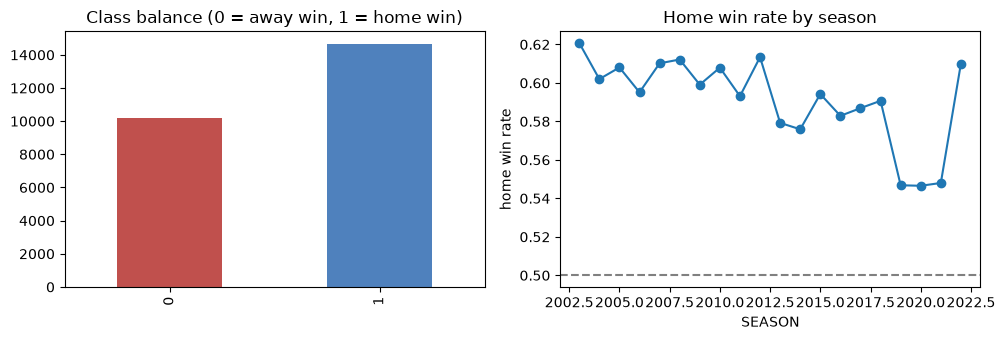

In [5]:
rate = g["HOME_TEAM_WINS"].mean()
print(f"home win rate: {rate:.1%}  (majority-class baseline accuracy)")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
g["HOME_TEAM_WINS"].value_counts().sort_index().plot.bar(ax=ax[0], color=["#c0504d", "#4f81bd"])
ax[0].set_title("Class balance (0 = away win, 1 = home win)"); ax[0].set_xlabel("")
by_season = g.groupby("SEASON")["HOME_TEAM_WINS"].mean()
by_season.plot(ax=ax[1], marker="o"); ax[1].axhline(0.5, ls="--", c="gray")
ax[1].set_title("Home win rate by season"); ax[1].set_ylabel("home win rate")
plt.tight_layout(); plt.show()

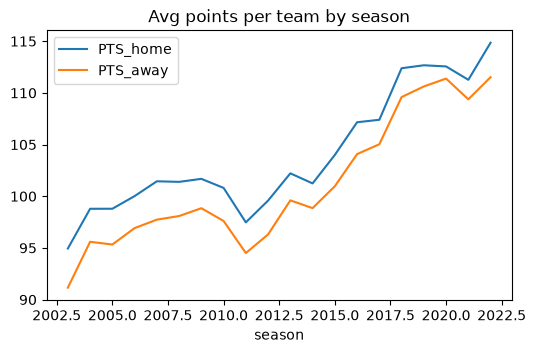

In [6]:
g[["PTS_home", "PTS_away"]].assign(season=g["SEASON"]).groupby("season").mean().plot(figsize=(6, 3.5), title="Avg points per team by season")
plt.show()

Home teams win about 59% of games, so the data is moderately imbalanced. Home advantage dips around the 2019-2021 COVID seasons. Scoring rises steadily over time (era drift).

## 4. Suitability and challenges
### Leakage: same-game stats reveal the answer

In [7]:
print("PTS_home > PTS_away predicts the label:", ((g["PTS_home"] > g["PTS_away"]).astype(int) == g["HOME_TEAM_WINS"]).mean())
print("FG_PCT_home > FG_PCT_away predicts the label:", ((g["FG_PCT_home"] > g["FG_PCT_away"]).astype(int) == g["HOME_TEAM_WINS"]).mean().round(3))

PTS_home > PTS_away predicts the label: 1.0
FG_PCT_home > FG_PCT_away predicts the label: 0.796


- **Leakage:** same-game box-score columns cannot be features. Features must come from *earlier* games only (e.g. rolling win %, rest days, Elo). `ranking.csv` standings also include that day's games, so only the *previous day's* snapshot is safe.
- **Time component / repeated entities:** the same 30 teams appear thousands of times, and games are ordered in time. We split **by season, never shuffled** (train 2003-2016, validation 2017-18, test 2019-22).
- **Size:** ~24.8K games is enough for classical models and a small neural net.
- **Shift:** the test set contains the COVID seasons with a weaker home edge.
- **Preprocessing ahead:** build pre-game features, home-minus-away differences, scale for linear/NN models.

## 5. Initial plan
- **Models:** logistic regression (baseline), random forest / gradient boosting, small MLP.
- **Evaluation:** accuracy vs the ~59% majority baseline, plus log-loss and ROC-AUC, on the season-based split.
- **Team split (proposed):** feature engineering, baseline models, tree/ensemble models, deep learning, evaluation + write-up.
- **Questions:** include playoffs? Is a COVID-heavy test set acceptable? Is a specific metric required?